# Egg prices with ReLU and softmax

This network has **two hidden layers with 30 neurons each**, with **ReLU in both
hidden layers**. Its output uses **softmax over 16 price ranges**. A weighted
average of the range centers converts those probabilities into a dollar forecast.

**Architecture:** 12 monthly log-price inputs → 30 ReLU neurons → 30 ReLU neurons
→ 16 output scores → softmax → probability-weighted price.

ReLU, $\max(0,z)$, lets the network represent nonlinear relationships. Softmax,
$p_k=e^{z_k}/\sum_j e^{z_j}$, converts output scores to probabilities summing to one.
Softmax is useful for this price-range classifier. Applied to a single output,
softmax would always return 1, which would not forecast a dollar price.

This is a different forecasting model from `gradient_descent.ipynb`: it uses
the last 12 prices as inputs and all available historical training examples,
rather than a line fitted to time over the last 24 months. Differences in accuracy
therefore reflect more than the activation functions alone.

Open inside the project with a Python 3 kernel. Dependencies: `numpy`,
`matplotlib`, `torch`, and `ipykernel`. The original data ends in April 2025.


In [1]:
from pathlib import Path
import csv
import hashlib
import os
import platform
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import torch
from torch import nn
import matplotlib.dates as mdates

plt.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.labelcolor': '#172554', 'text.color': '#172554',
    'axes.titleweight': 'bold', 'font.size': 10,
})
COLORS = {'observed': '#172554', 'gd': '#2563eb', 'naive': '#b45309',
          'actual': '#0f766e'}

# Locate the project from either the repository root or analysis/.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'data' / 'APU0000708111.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open the notebook inside the egg-onomics project.')
INPUT = ROOT / 'data' / 'APU0000708111.csv'
# Keep this experiment separate from the R outputs; override for a scratch run.
OUT = Path(os.environ.get('EGG_NN_OUTPUT', str(ROOT / 'results' / 'neural_network')))
OUT.mkdir(parents=True, exist_ok=True)

with INPUT.open(newline='', encoding='utf-8-sig') as handle:
    rows = list(csv.DictReader(handle))
dates = np.array([r['observation_date'] for r in rows], dtype='datetime64[M]')
prices = np.array([float(r['APU0000708111']) for r in rows])
month_index = np.arange(len(prices), dtype=float)
expected = np.arange(np.datetime64('1980-01', 'M'), np.datetime64('2025-05', 'M'))
assert len(prices) == 544 and np.array_equal(dates, expected)
assert np.isfinite(prices).all() and (prices > 0).all()
source_md5 = hashlib.md5(INPUT.read_bytes()).hexdigest()
assert source_md5 == 'bf246189cbf9d52a5da338e57f838d30'
print(f'{len(prices)} observed monthly prices: {dates[0]} to {dates[-1]}')
print('Missing months: 0. Missing prices: 0. No filling or interpolation.')

print('PyTorch', torch.__version__)


544 observed monthly prices: 1980-01 to 2025-04
Missing months: 0. Missing prices: 0. No filling or interpolation.
PyTorch 2.14.1+cpu


## Fixed inputs and price ranges

Each supervised example uses the previous 12 observed log prices to classify
the next month's dollar price. For example, January–December prices are inputs
for predicting January of the following year. All target dates remain within
the available fitting history.

We define 16 equal-width ranges from **$0 to $8**, in $0.50 steps, before fitting
any model. The centers are $0.25, $0.75, …, $7.75. Predictions are weighted
averages of these centers and are therefore bounded by **$0.25 and $7.75**.
The classifier cannot extrapolate beyond that support. The chosen range is a
fixed modeling assumption, not an estimate from the validation or test prices.

We standardize each lag feature using only the fitting examples. Hyperparameters
are fixed for this demonstration: seed 42, 800 full-batch Adam updates, learning
rate 0.003, and weight decay 0.0001. Adam is an adaptive gradient-based optimizer;
backpropagation computes the derivatives used to update the network weights.


In [2]:
LAGS = 12
HIDDEN = 30
HORIZON = 3
BIN_EDGES = np.linspace(0.0, 8.0, 17)
BIN_CENTERS = (BIN_EDGES[:-1] + BIN_EDGES[1:]) / 2
N_BINS = len(BIN_CENTERS)
EPOCHS = 800
LEARNING_RATE = 0.003
WEIGHT_DECAY = 1e-4
SEED = 42

torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)

class EggPriceNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.logits = nn.Sequential(
            nn.Linear(LAGS, HIDDEN),
            nn.ReLU(),
            nn.Linear(HIDDEN, HIDDEN),
            nn.ReLU(),
            nn.Linear(HIDDEN, N_BINS),
        )
        self.softmax = nn.Softmax(dim=-1)

    def forward(self, x):
        return self.softmax(self.logits(x))

def supervised_history(end):
    target_ids = np.arange(LAGS, end)
    X = np.stack([np.log(prices[i - LAGS:i]) for i in target_ids])
    targets = prices[target_ids]
    if not np.all((targets >= BIN_EDGES[0]) & (targets < BIN_EDGES[-1])):
        raise ValueError('Training prices fall outside the fixed price-range support.')
    labels = np.digitize(targets, BIN_EDGES[1:-1]).astype(np.int64)
    return X, labels, target_ids

example_network = EggPriceNetwork()
parameter_count = sum(p.numel() for p in example_network.parameters())
assert parameter_count == (12 + 1) * 30 + (30 + 1) * 30 + (30 + 1) * 16 == 1816
print(example_network)
print(f'Trainable parameters: {parameter_count:,}; hidden neurons: 60; output neurons: 16')


EggPriceNetwork(
  (logits): Sequential(
    (0): Linear(in_features=12, out_features=30, bias=True)
    (1): ReLU()
    (2): Linear(in_features=30, out_features=30, bias=True)
    (3): ReLU()
    (4): Linear(in_features=30, out_features=16, bias=True)
  )
  (softmax): Softmax(dim=-1)
)
Trainable parameters: 1,816; hidden neurons: 60; output neurons: 16


## Training and recursive forecasts

Training minimizes cross-entropy between output scores and the observed price
range. PyTorch's `CrossEntropyLoss` already includes the log-softmax operation,
so we feed it **raw scores**, not probabilities. We apply softmax when predicting.

For the first forecast, the network reads the last 12 observed prices. For the
second and third forecasts, it appends its own previous point forecast to the
input history. It never reads held-out prices inside a three-month forecast.

The probability bars for later steps are conditional on that recursively
constructed history. They are not calibrated prediction intervals or a full
propagation of uncertainty across future paths.


In [3]:
def fit_network(end):
    torch.manual_seed(SEED)
    X, labels, target_ids = supervised_history(end)
    center, scale = X.mean(axis=0), X.std(axis=0)
    scale = np.maximum(scale, 1e-8)
    features = torch.tensor((X - center) / scale, dtype=torch.float32)
    targets = torch.tensor(labels, dtype=torch.long)
    network = EggPriceNetwork()
    optimizer = torch.optim.Adam(network.parameters(), lr=LEARNING_RATE,
                                 weight_decay=WEIGHT_DECAY)
    criterion = nn.CrossEntropyLoss()
    losses = []
    network.train()
    with torch.no_grad():
        losses.append(float(criterion(network.logits(features), targets)))
    for _ in range(EPOCHS):
        optimizer.zero_grad()
        loss = criterion(network.logits(features), targets)
        if not torch.isfinite(loss):
            raise FloatingPointError('Nonfinite training loss')
        loss.backward()
        optimizer.step()
        with torch.no_grad():
            losses.append(float(criterion(network.logits(features), targets)))
    network.eval()
    with torch.no_grad():
        training_accuracy = float((network(features).argmax(dim=1) == targets).float().mean())
    assert target_ids[-1] == end - 1
    assert len(target_ids) == end - LAGS
    assert losses[-1] < losses[0]
    assert all(torch.isfinite(p).all() for p in network.parameters())
    return dict(network=network, center=center, scale=scale, end=end,
                losses=np.array(losses), training_examples=len(targets),
                training_accuracy=training_accuracy)

def forecast_network(model, available_prices):
    history = list(np.asarray(available_prices, dtype=float))
    assert len(history) == model['end']
    forecasts, probability_rows = [], []
    for _ in range(HORIZON):
        features = (np.log(history[-LAGS:]) - model['center']) / model['scale']
        with torch.no_grad():
            probabilities = model['network'](
                torch.tensor(features[None, :], dtype=torch.float32)
            ).numpy()[0].astype(float)
        assert np.isfinite(probabilities).all() and (probabilities >= 0).all()
        assert np.isclose(probabilities.sum(), 1.0, atol=1e-6)
        point = float(probabilities @ BIN_CENTERS)
        forecasts.append(point)
        probability_rows.append(probabilities)
        history.append(point)
    return np.array(forecasts), np.array(probability_rows)

def score(actual, forecast):
    error = actual - forecast
    return dict(MAE=float(np.mean(np.abs(error))),
                RMSE=float(np.sqrt(np.mean(error ** 2))),
                MAPE=float(100 * np.mean(np.abs(error / actual))))


## Evaluation on the original three-month splits

Validation forecasts cover November 2024–January 2025, test forecasts cover
February–April 2025, and the final historical forecast covers May–July 2025.
We refit independently at each origin using only the history available then.
The naive baseline repeats the last observed price. We do not select epochs,
architecture, or bin ranges using the three test outcomes.

Training loss and training classification accuracy show how well the network
learns its historical examples. Hold-out **dollar RMSE and MAE** determine whether
its point forecasts improve on naive forecasting.


In [4]:
origins = {'Validation': len(prices) - 6, 'Test': len(prices) - 3,
           'Future': len(prices)}
experiments, accuracy_rows, prediction_rows, probability_rows = {}, [], [], []
fit_rows, loss_rows = [], []
for stage, end in origins.items():
    model = fit_network(end)
    forecast, probabilities = forecast_network(model, prices[:end])
    forecast_dates = dates[end - 1] + np.arange(1, HORIZON + 1).astype('timedelta64[M]')
    naive = np.repeat(prices[end - 1], HORIZON)
    actual = prices[end:end + HORIZON] if stage != 'Future' else None
    experiments[stage] = dict(model=model, dates=forecast_dates,
        forecasts={'ReLU softmax network': forecast, 'Naive': naive},
        probabilities=probabilities, actual=actual)
    fit_rows.append(dict(stage=stage, history_end=str(dates[end - 1]),
        training_examples=model['training_examples'], parameters=parameter_count,
        initial_cross_entropy=model['losses'][0], final_cross_entropy=model['losses'][-1],
        training_bin_accuracy=model['training_accuracy']))
    for epoch, loss in enumerate(model['losses']):
        loss_rows.append(dict(stage=stage, epoch=epoch, cross_entropy=float(loss)))
    for method, values in experiments[stage]['forecasts'].items():
        if actual is not None:
            accuracy_rows.append(dict(stage=stage, model=method, **score(actual, values)))
        for j, date in enumerate(forecast_dates):
            prediction_rows.append(dict(stage=stage, model=method, date=str(date),
                forecast=float(values[j]), actual='' if actual is None else float(actual[j])))
    for j, date in enumerate(forecast_dates):
        for k, probability in enumerate(probabilities[j]):
            probability_rows.append(dict(stage=stage, date=str(date), bin_id=k,
                lower=float(BIN_EDGES[k]), upper=float(BIN_EDGES[k + 1]),
                center=float(BIN_CENTERS[k]), probability=float(probability)))

print(f"{'Stage':<12} {'Model':<22} {'MAE':>8} {'RMSE':>8} {'MAPE %':>9}")
for row in accuracy_rows:
    print(f"{row['stage']:<12} {row['model']:<22} {row['MAE']:8.3f} "
          f"{row['RMSE']:8.3f} {row['MAPE']:9.2f}")
for row in fit_rows:
    print(f"{row['stage']}: {row['training_examples']} examples; "
          f"cross-entropy {row['initial_cross_entropy']:.3f} → {row['final_cross_entropy']:.3f}; "
          f"training bin accuracy {row['training_bin_accuracy']:.1%}")
print('\nHistorical forecasts from April 2025, dollars per dozen:')
for date, point in zip(experiments['Future']['dates'],
                       experiments['Future']['forecasts']['ReLU softmax network']):
    print(f'{date}: ${point:.3f}')


Stage        Model                       MAE     RMSE    MAPE %
Validation   ReLU softmax network      1.456    1.572     33.05
Validation   Naive                     0.879    1.031     19.44
Test         ReLU softmax network      1.904    1.961     32.70
Test         Naive                     0.796    0.921     13.26
Validation: 526 examples; cross-entropy 2.813 → 0.182; training bin accuracy 93.5%
Test: 529 examples; cross-entropy 2.813 → 0.198; training bin accuracy 92.2%
Future: 532 examples; cross-entropy 2.816 → 0.188; training bin accuracy 92.5%

Historical forecasts from April 2025, dollars per dozen:
2025-05: $3.758
2025-06: $3.234
2025-07: $2.262


## Forecasts and learned probabilities

The forecast panels compare the network's probability-weighted prices with the
naive baseline. The probability plot shows all 16 output neurons for each of the
three historical future forecasts. A more concentrated distribution means the
classifier assigns more weight to fewer price ranges; it does not by itself
establish reliable uncertainty estimates.


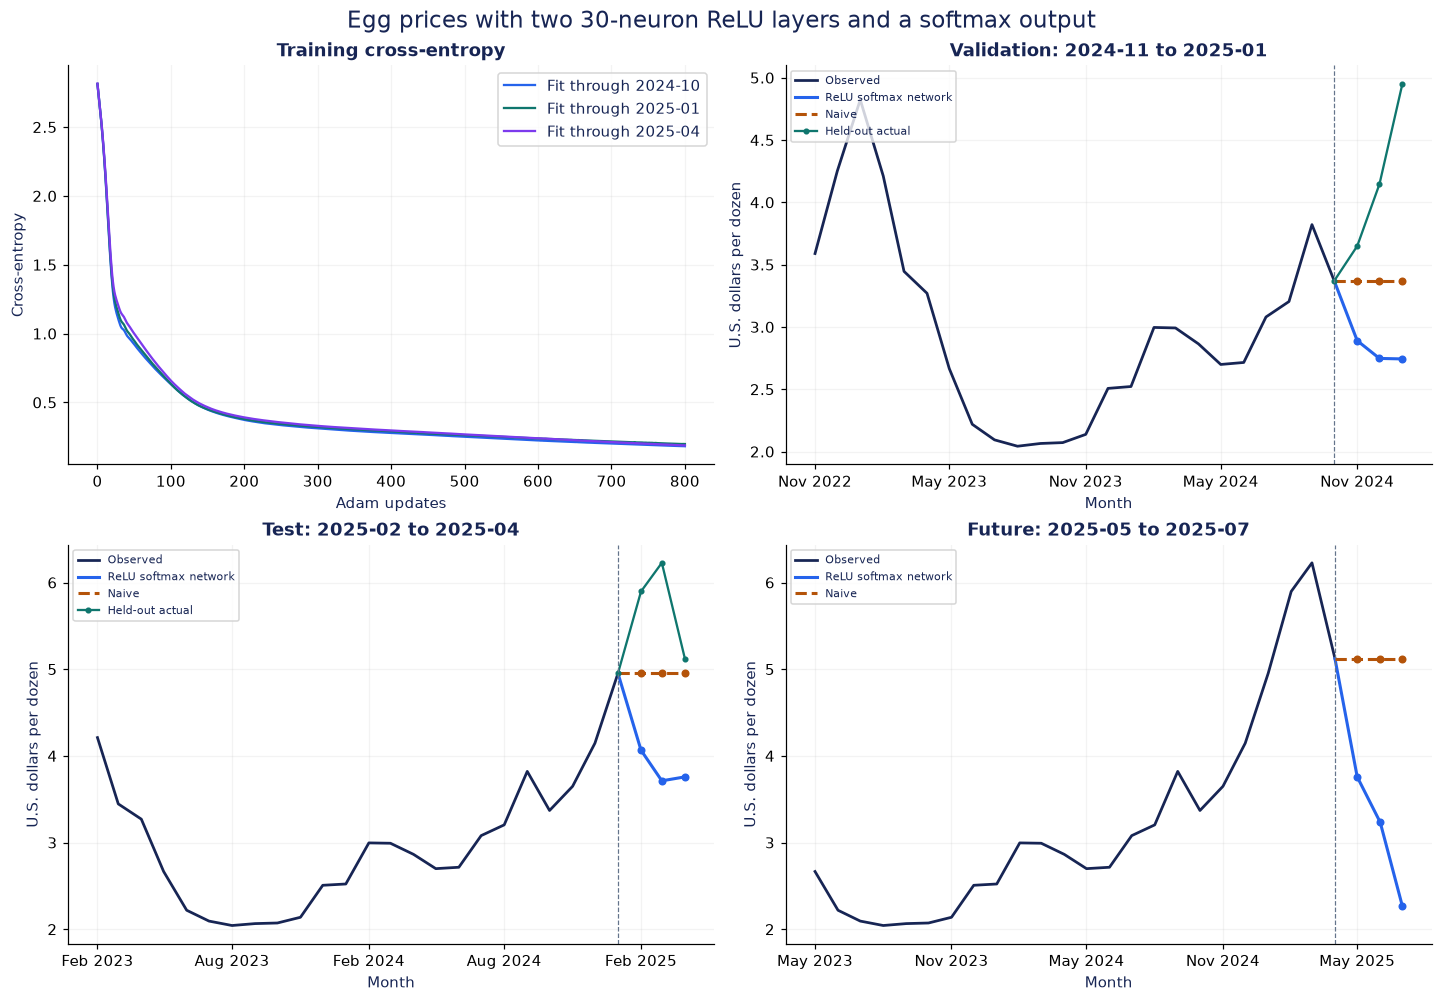

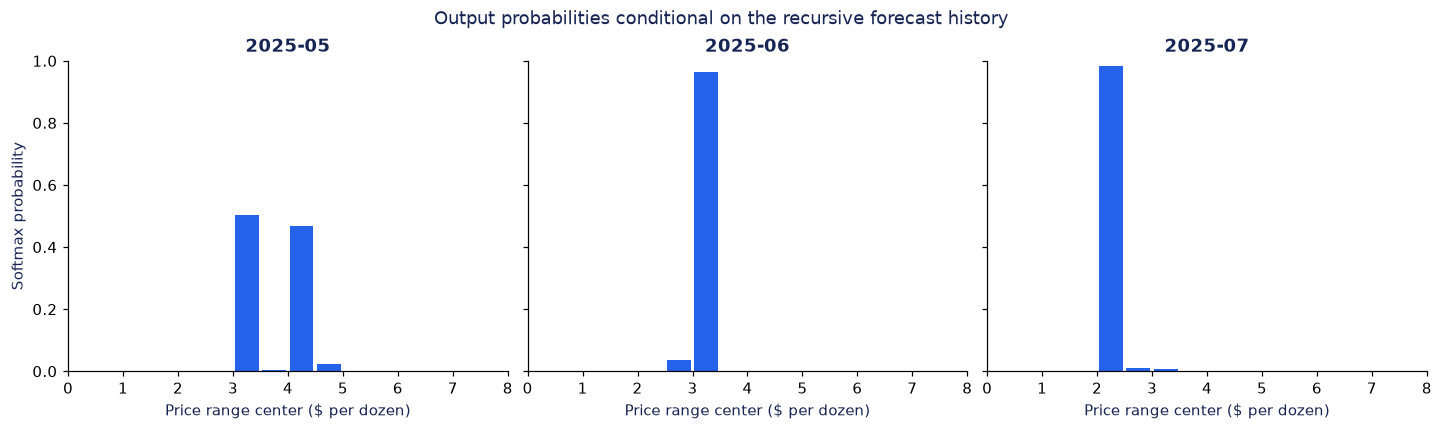

In [5]:
def draw_forecast(ax, stage):
    result = experiments[stage]
    end = result['model']['end']
    past = slice(max(0, end - 24), end)
    origin = dates[end - 1].astype('datetime64[D]')
    next_dates = result['dates'].astype('datetime64[D]')
    joined_dates = np.concatenate([[origin], next_dates])
    ax.plot(dates[past].astype('datetime64[D]'), prices[past],
            color=COLORS['observed'], label='Observed', lw=1.8)
    for method, color, style in [('ReLU softmax network', COLORS['gd'], '-'),
                                 ('Naive', COLORS['naive'], '--')]:
        values = result['forecasts'][method]
        ax.plot(joined_dates, np.r_[prices[end - 1], values],
                color=color, ls=style, lw=2, label=method)
        ax.scatter(next_dates, values, color=color, s=18, zorder=3)
    if result['actual'] is not None:
        ax.plot(joined_dates, np.r_[prices[end - 1], result['actual']],
                color=COLORS['actual'], marker='o', ms=3, label='Held-out actual')
    ax.axvline(origin, color='#64748b', ls='--', lw=0.8)
    ax.set(title=f"{stage}: {result['dates'][0]} to {result['dates'][-1]}",
           xlabel='Month', ylabel='U.S. dollars per dozen')
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    ax.legend(fontsize=7, loc='upper left')
    ax.grid(alpha=0.15)

fig, axes = plt.subplots(2, 2, figsize=(13, 9), layout='constrained')
for stage, color in zip(origins, ['#2563eb', '#0f766e', '#7c3aed']):
    losses = experiments[stage]['model']['losses']
    fit_end = dates[experiments[stage]['model']['end'] - 1]
    axes[0, 0].plot(np.arange(len(losses)), losses, color=color, label=f'Fit through {fit_end}')
axes[0, 0].set(title='Training cross-entropy', xlabel='Adam updates', ylabel='Cross-entropy')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.15)
for ax, stage in zip([axes[0, 1], axes[1, 0], axes[1, 1]], origins):
    draw_forecast(ax, stage)
fig.suptitle('Egg prices with two 30-neuron ReLU layers and a softmax output', fontsize=15)
fig.savefig(OUT / 'neural_network_comparison.png', dpi=160, bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True, layout='constrained')
for ax, date, probabilities in zip(axes, experiments['Future']['dates'],
                                  experiments['Future']['probabilities']):
    ax.bar(BIN_CENTERS, probabilities, width=0.43, color='#2563eb')
    ax.set(title=str(date), xlabel='Price range center ($ per dozen)', xlim=(0, 8), ylim=(0, 1))
axes[0].set_ylabel('Softmax probability')
fig.suptitle('Output probabilities conditional on the recursive forecast history')
fig.savefig(OUT / 'softmax_probabilities.png', dpi=160, bbox_inches='tight')
plt.show()


## Checks and saved results

This network has 1,816 trainable parameters and at most 532 supervised historical
examples, so fitting the history well does not guarantee accurate forecasts.
Softmax price ranges impose a finite support and a discretization error. Three
test months are limited evidence about performance in other periods.

We check architecture, parameter count, date boundaries, probability sums,
reconstruction of dollar forecasts, and the absence of held-out prices inside
recursive predictions. Artifacts are saved separately in `results/neural_network/`.

The implementation follows the official PyTorch documentation for
[ReLU](https://docs.pytorch.org/docs/stable/generated/torch.nn.ReLU.html),
[Softmax](https://docs.pytorch.org/docs/stable/generated/torch.nn.Softmax.html), and
[CrossEntropyLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html).


In [6]:
assert [str(d) for d in experiments['Validation']['dates']] == ['2024-11', '2024-12', '2025-01']
assert [str(d) for d in experiments['Test']['dates']] == ['2025-02', '2025-03', '2025-04']
assert [str(d) for d in experiments['Future']['dates']] == ['2025-05', '2025-06', '2025-07']
for stage, result in experiments.items():
    model = result['model']
    linears = [m for m in model['network'].logits if isinstance(m, nn.Linear)]
    assert [(m.in_features, m.out_features) for m in linears] == [(12, 30), (30, 30), (30, 16)]
    assert sum(isinstance(m, nn.ReLU) for m in model['network'].logits) == 2
    assert dates[model['end'] - 1] < result['dates'][0]
    assert np.allclose(result['probabilities'].sum(axis=1), 1, atol=1e-6)
    assert np.allclose(result['probabilities'] @ BIN_CENTERS,
                       result['forecasts']['ReLU softmax network'])
    repeated, _ = forecast_network(model, prices[:model['end']].copy())
    assert np.array_equal(repeated, result['forecasts']['ReLU softmax network'])
    torch.save(dict(state_dict=model['network'].state_dict(),
        feature_mean=model['center'].tolist(), feature_scale=model['scale'].tolist(),
        bin_edges=BIN_EDGES.tolist(), history_end=str(dates[model['end'] - 1]),
        architecture=[12, 30, 30, 16], seed=SEED, epochs=EPOCHS,
        learning_rate=LEARNING_RATE, weight_decay=WEIGHT_DECAY),
        OUT / f"{stage.lower()}_model.pt")

def save_csv(filename, rows):
    with (OUT / filename).open('w', newline='', encoding='utf-8') as handle:
        writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)

save_csv('accuracy.csv', accuracy_rows)
save_csv('predictions.csv', prediction_rows)
save_csv('probabilities.csv', probability_rows)
save_csv('fits.csv', fit_rows)
save_csv('learning_curves.csv', loss_rows)
(OUT / 'run_info.txt').write_text(
    f'Python {platform.python_version()}\nNumPy {np.__version__}\n'
    f'Matplotlib {matplotlib.__version__}\nPyTorch {torch.__version__}\n'
    f'Source MD5 {source_md5}\nSeed {SEED}; epochs {EPOCHS}; Adam lr {LEARNING_RATE}\n'
    f'Weight decay {WEIGHT_DECAY}; architecture 12-30-30-16\n'
    'Two ReLU hidden layers; softmax price-range output.\n'
    '16 fixed half-dollar ranges from $0 to $8; point forecasts bounded by centers.\n',
    encoding='utf-8')
for stage in ['Validation', 'Test']:
    scores = {r['model']: r['RMSE'] for r in accuracy_rows if r['stage'] == stage}
    winner = min(scores, key=scores.get)
    print(f'{stage}: {winner} has lower dollar RMSE in this three-month window.')
print('Checks passed. Saved figures, CSVs, model weights, and training settings to:')
print(OUT)


Validation: Naive has lower dollar RMSE in this three-month window.
Test: Naive has lower dollar RMSE in this three-month window.
Checks passed. Saved figures, CSVs, model weights, and training settings to:
C:\Users\Kelvin\Desktop\Folders\GitHub\egg-onomics\results\neural_network
